# Reward Modeling — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/11-advanced-fine-tuning/notebooks/reward-modeling.ipynb) · [Course notes](../../../courses/11-advanced-fine-tuning/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# Reward Modeling
Imagine that you're working as a machine learning engineer for a large technology company that wants to integrate advanced language models into its suite of AI-powered products. Your task is to evaluate and select the best large language model (LLM) that can understand and follow complex instructions, improve the quality of automated customer service, and generate high-quality responses.

However, simply choosing a powerful LLM isn't enough. To truly excel in these tasks, the model should be fine-tuned to align with specific goals and criteria. This is where reward models come into the picture. By training a reward model, you can guide the LLM to prioritize certain behaviors, ensuring it generates responses that not only meet technical standards but also align with the company's values and objectives.

In this hands-on lab, you dive into the process of creating and training a reward model by using the transformer reinforcement learner (trl) library from Hugging Face. You learn how to set up the environment, define the rewards that shape the model's behavior, and fine-tune the LLM to perform with precision. This project equips you with the skills to implement reward models in real-world applications, enhancing the effectiveness and quality of AI-powered products.


## __Table of Contents__

<ol>
    <li><a href="#Objectives">Objectives</a></li>
    </ul>
    <li><a href="#Setup">Setup</a></li>
    <ul>
        <li><a href="#Installing-required-libraries">Installing required libraries</a></li>
        <li><a href="#Importing-required-libraries">Importing required libraries</a></li>
        <li><a href="#Defining-helper-functions">Defining helper functions</a></li>
    </ul>
    <li><a href="#Dataset">Data set</a></li>
    <ul>
        <li><a href="#Purpose">Purpose</a></li>
        <li><a href="#Applications">Applications</a></li>
        <li><a href="#Dataset-features">Data set features</a></li>
    </ul>
    <li><a href="#Model-and-tokenizer-Setup">Model and tokenizer setup</a></li>
    <li><a href="#Preprocessing">Preprocessing</a></li>
    <ul>
        <li><a href="#LoRA-configuration">LoRA configuration</a></li>
        <li><a href="#Training-arguments">Training arguments</a></li>
        <li><a href="#Reward-Trainer">Reward trainer</a></li>
    </ul>
    <li><a href="#Evaluating-the-model">Evaluating the model</a></li>
    <li><a href="#Exercise">Exercise</a></li>
</ol>


# Objectives
After completing this lab, you are able to:

- Understand the concept of reward modeling in machine learning
- Explore and preprocess a data set for reward modeling tasks
- Set up and configure a GPT-2 model for sequence classification
- Tokenize and prepare text data for model training
- Evaluate model performance using pairwise comparison of responses
- Apply preprocessing and evaluation techniques to different subsets of data
- Understand important concepts related to transformers and reward modeling
- Implement special tokens in the tokenizer and configure the model accordingly


# Setup
## Installing required libraries
Before you start, make sure that you have all of the necessary libraries installed. You can run the following commands to install them:


After running the above code, restart the kernel by running the following cell:


If the above code did not work for you and the kernel did not restart, you can restart the kernel by clicking on the restart kernel button instead:
<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/OHxKDI9iuTHH2o6bJOETqg/restart-jupyterlab-kernel.png" width="100%" alt="restart the kernel button image"  />


## Importing required libraries


In [2]:
import json
from datasets import load_dataset, DatasetDict
import torch
from transformers import GPT2Tokenizer, GPT2ForSequenceClassification, TrainingArguments
from peft import LoraConfig, TaskType
from transformers import TrainingArguments
from trl import RewardTrainer
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

def warn(*args, **kwargs):
    pass
warnings.warn = warn

<repository>/.venv-legacy/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Matplotlib is building the font cache; this may take a moment.


## Defining helper functions


In [3]:
def save_to_json(data, file_path):
    """
    Save a dictionary to a JSON file.

    Args:
        data (dict): The dictionary to save.
        file_path (str): The path to the JSON file.
    """
    with open(file_path, 'w') as json_file:
        json.dump(data, json_file, indent=4)
    print(f'Data successfully saved to {file_path}')

def load_from_json(file_path):
    """
    Load data from a JSON file.

    Args:
        file_path (str): The path to the JSON file.

    Returns:
        dict: The data loaded from the JSON file.
    """
    with open(file_path, 'r') as json_file:
        data = json.load(json_file)
    return data


## Data set

In this section, you load a data set that is used for training the reward model. In this lab, you use the Dahoas/synthetic-instruct-gptj-pairwise data set from Hugging Face, a synthetic data set that is designed for training and evaluating instruction-following models. This data set includes pairs of prompts and responses, where one response is preferred over the other. The primary use case is to train models to distinguish between better and worse responses, essential for tasks like reinforcement learning with human feedback (RLHF).

### Purpose

This data set helps train models for better understanding and following instructions by learning from pairs of good and bad responses. This is particularly useful for improving the quality of generated responses in dialogue systems and other AI applications that require understanding and generating natural language instructions.

### Applications
- **Reinforcement learning**: Enhancing models to prefer better responses based on feedback
- **Fine-tuning language models**: Improving the performance of models on instruction-following tasks
- **Evaluation**: Assessing the ability of models to distinguish between high- and low-quality responses


In [4]:
dataset = load_dataset('Dahoas/synthetic-instruct-gptj-pairwise')
print(dataset)

Generating train split:   0%|                 | 0/33143 [00:00<?, ? examples/s]

Generating train split: 100%|█| 33143/33143 [00:00<00:00, 827579.37 examples/s]

DatasetDict({
    train: Dataset({
        features: ['prompt', 'chosen', 'rejected'],
        num_rows: 33143
    })
})


### Data set features

To get a better understanding of the data set, let's inspect a few samples. First, print out the `prompt`, `chosen`, and `rejected` responses for the first 10 examples in the training set. This gives an insight into the type of data on which you are working and how it is structured.

```Prompt:``` A text prompt that the model should respond to

```Chosen:``` The preferred response to the prompt

```Rejected:``` The less preferred response to the prompt


In [5]:
for i in range(10):
    print('prompt')
    print(dataset['train'][i]['prompt'], '\n')
    print('chosen')
    print(dataset['train'][i]['chosen'], '\n')
    print('rejected')
    print(dataset['train'][i]['rejected'], '\n')
    print('---------------------------\n')

prompt
I was wondering if you could walk me through the process of setting up a hydroponic garden for herbs. 

chosen
Sure! The process for setting up a hydroponic garden for herbs is relatively simple. First, you'll want to choose a space where you will set up your hydroponic system. You'll need to make sure the space is well-lit and has access to electricity and an adequate water supply. Next, you'll need to choose the type of hydroponic system you want to use. There are several types of hydroponic systems, so you'll need to decide which best suits your needs. Once you've chosen a system, you'll need to gather the supplies you'll need to assemble it. This includes things like pumps, growing trays, grow lights, and nutrients. Once you've assembled the system, you'll need to add your choice of herbs to the system. Lastly, you'll need to monitor and adjust the system as needed to ensure your herbs are getting the correct amount of light, water, and nutrients. 

rejected
How do I store a

## Model and tokenizer setup
In this section, you set up the tokenizer and the model for training. You can use the GPT-2 model for sequence classification, which helps in determining the quality of responses.

Next, specify the model name or path as "gpt2". To initialize the tokenizer and model, use `GPT2Tokenizer.from_pretrained` and `GPT2ForSequenceClassification.from_pretrained`, respectively, with `num_labels` set to 1 for ranking (a numerical score value). To handle padding, set the `pad_token` of the tokenizer to be the same as the `eos_token` (end-of-sequence token). Similarly, configure the model to use the `eos_token_id` as the `pad_token_id`. This setup ensures that the tokenizer and model are correctly initialized and prepared for sequence classification tasks with GPT-2.


In [6]:
model_name_or_path = 'gpt2'
tokenizer = GPT2Tokenizer.from_pretrained(model_name_or_path, use_fast=True)
model = GPT2ForSequenceClassification.from_pretrained(model_name_or_path, num_labels=1)
tokenizer.pad_token = tokenizer.eos_token
model.config.pad_token_id = model.config.eos_token_id
max_length = 1024

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Next, preprocess the data set for training. Then combine the prompt with the chosen and rejected responses into a format suitable for input into the model. This process helps create clear input-output pairs for the model to learn from.

`Lambda Function`: Define a lambda function `get_res` that takes the data set and a response type (chosen or rejected) and combines the prompt with the respective response. Each entry is formatted as a dialogue between "Human" and "Assistant".


In [7]:
get_res = lambda dataset, res: ['\n\nHuman: ' + prompt + '\n\nAssistant: ' + resp for prompt, resp in zip(dataset['train']['prompt'], dataset['train'][res])]

`Chosen Samples`: Apply the `get_res` function to create a list of chosen samples.

`Rejected Samples`: Similarly, create a list of rejected samples using the same function.

After applying the function,  you get the following results.


In [8]:
chosen_samples = get_res(dataset, 'chosen')
rejected_samples = get_res(dataset, 'rejected')
print('chosen', chosen_samples[0])
print('rejected', rejected_samples[0])

chosen 

Human: I was wondering if you could walk me through the process of setting up a hydroponic garden for herbs.

Assistant: Sure! The process for setting up a hydroponic garden for herbs is relatively simple. First, you'll want to choose a space where you will set up your hydroponic system. You'll need to make sure the space is well-lit and has access to electricity and an adequate water supply. Next, you'll need to choose the type of hydroponic system you want to use. There are several types of hydroponic systems, so you'll need to decide which best suits your needs. Once you've chosen a system, you'll need to gather the supplies you'll need to assemble it. This includes things like pumps, growing trays, grow lights, and nutrients. Once you've assembled the system, you'll need to add your choice of herbs to the system. Lastly, you'll need to monitor and adjust the system as needed to ensure your herbs are getting the correct amount of light, water, and nutrients.
rejected 

Huma

To facilitate the training process, create new columns in the data set that combine the prompt with chosen and rejected responses. This combination helps in evaluating the responses in a structured dialogue format.

**Function definition**: Define a function `add_combined_columns` that takes an example (a single data point) and adds two new columns:
- `prompt_chosen`: Combines the `prompt` with the `chosen` response in the same labeled format.
- `prompt_rejected`: Combines the `prompt` with the `rejected` response in the same labeled format.

**Apply function**: The `map` method is used to apply this function to each example in the training split of the data set. This method iterates over all the examples and modifies them in place.


In [9]:
def add_combined_columns(example):
    example['prompt_chosen'] = '\n\nHuman: ' + example['prompt'] + '\n\nAssistant: ' + example['chosen']
    example['prompt_rejected'] = '\n\nHuman: ' + example['prompt'] + '\n\nAssistant: ' + example['rejected']
    return example
dataset['train'] = dataset['train'].map(add_combined_columns)

Map:   0%|                                    | 0/33143 [00:00<?, ? examples/s]

Map:  17%|███▊                  | 5656/33143 [00:00<00:00, 56077.27 examples/s]

Map:  35%|███████▎             | 11475/33143 [00:00<00:00, 57308.25 examples/s]

Map:  61%|████████████▊        | 20258/33143 [00:00<00:00, 57996.66 examples/s]

Map:  88%|██████████████████▍  | 29131/33143 [00:00<00:00, 58145.52 examples/s]

Map: 100%|█████████████████████| 33143/33143 [00:00<00:00, 57429.78 examples/s]

When using pretrained transformers for classification tasks, understanding the maximum sequence length supported by the model is crucial, as pretrained transformers have a fixed maximum token length, for example, GPT-2 has 1024 tokens. Inputs longer than this are truncated, potentially losing important information. So a function is written to determine the max length.


In [10]:
get_max_len = lambda samples: max([len(sample) for sample in samples])
get_max_len

<function __main__.<lambda>(samples)>

In [11]:
print('rejected samples length', get_max_len(rejected_samples))
print('chosen samples length', get_max_len(chosen_samples))

rejected samples length 5011
chosen samples length 3167


Sometimes, you might want to identify samples shorter than a specified maximum length. This can be useful for filtering or handling special cases during preprocessing.

The lambda function `find_short` takes a data set and a maximum length (`max_length`) as input. It uses a list comprehension to iterate over each example in the data set, enumerating both the index and the (chosen, rejected) pair. It zips `prompt_chosen` and `prompt_rejected` to pair each chosen response with its corresponding rejected response. For each pair, it checks if the length of either `chosen` or `rejected` is less than the specified `max_length`. If the condition is met, the index of that pair is included in the resulting list. The resulting list contains the index of all examples where either `prompt_chosen` or `prompt_rejected` is shorter than the specified `max_length`.


In [12]:
find_short = lambda dataset, max_length: [i for i, (chosen, rejected) in enumerate(zip(dataset['prompt_chosen'], dataset['prompt_rejected'])) if len(chosen) < max_length or len(rejected) < max_length]

To ensure that your data set only includes samples that meet the required length criteria, filter out any samples that are shorter than the specified `max_length`. This step is important for maintaining consistency in the input data for the model.

Now, use the GPT-2 model for classification with a max length of 1024. First, set the maximum length (`max_length`) to 1024. The `find_short` function is then called with the training data set (`dataset['train']`) and this maximum length as arguments to find indices of examples where either `prompt_chosen` or `prompt_rejected` is shorter than the specified `max_length`. The resulting index (`subset_indices`) is used to create a subset of the training data set by selecting only the examples at these indices. The training data set (`dataset['train']`) is updated to this subset, and the `subset_indices` are returned or printed.


In [13]:
max_length = 1024
subset_indices = find_short(dataset['train'], max_length)
dataset['train'] = dataset['train'].select(subset_indices)
subset_indices[0:10]

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


 The ```preprocess_function``` tokenizes the ```prompt_chosen``` and ```prompt_rejected``` keys, which are crucial for the RewardTrainer. The ```chosen``` key represents the preferred responses, while the ```rejected``` key represents the less preferred responses.
 Tokenizing these keys allows the model to process and understand the differences between high-quality and low-quality responses. By providing both ```chosen``` and ```rejected``` inputs, the RewardTrainer can learn to distinguish and prioritize better responses, which is essential for training models to follow instructions effectively.


In [14]:
def preprocess_function(examples):
    tokenized_chosen = tokenizer(examples['prompt_chosen'], truncation=True, max_length=max_length, padding='max_length')
    tokenized_rejected = tokenizer(examples['prompt_rejected'], truncation=True, max_length=max_length, padding='max_length')
    return {'input_ids_chosen': tokenized_chosen['input_ids'], 'attention_mask_chosen': tokenized_chosen['attention_mask'], 'input_ids_rejected': tokenized_rejected['input_ids'], 'attention_mask_rejected': tokenized_rejected['attention_mask']}


The `input_ids_chosen` and `input_ids_rejected` fields contain the token IDs for the `chosen` and `rejected` responses, respectively, which are the numerical representations of the text used by the model. The `attention_mask_chosen` and `attention_mask_rejected` fields contain the attention masks for the `chosen` and `rejected` responses, respectively, which indicates tokens that should be attended to (1) and should ignore (0). These fields are crucial for the `RewardTrainer` because they provide the necessary tokenized inputs and attention masks for both the preferred and less preferred responses. By comparing the token IDs and attention patterns of the `chosen` and `rejected` responses, the `RewardTrainer` can distinguish between high- and low-quality responses, thereby improving the model's ability to prioritize better responses in instruction-following tasks.

You can apply the ```reprocess_function``` to one sample:


In [15]:
example = preprocess_function(dataset['train'][0])
example.keys()

dict_keys(['input_ids_chosen', 'attention_mask_chosen', 'input_ids_rejected', 'attention_mask_rejected'])

Now, create a dictionary with 'chosen' and 'rejected' samples from the training data set. This dictionary is created to make it easier to validate the model later.


In [16]:
train_str = {'chosen': [sample for sample in dataset['train']['prompt_chosen']], 'rejected': [sample for sample in dataset['train']['prompt_rejected']]}

The code applies the preprocess_function to each example in the training data set using the map method, which tokenizes the ```prompt_chosen``` and ```prompt_rejected``` texts. The `batched = True` parameter allows the function to process multiple examples at once, improving efficiency. Additionally, the `remove_columns` parameter specifies a list of columns (```prompt```, ```chosen```, ```rejected```, ```prompt_chosen```, ```prompt_rejected```) to be removed from the data set after processing. This ensures that only the tokenized inputs and attention masks generated by `preprocess_function` are retained, simplifying the data set structure and making it more suitable for model training and validation.


In [17]:
dataset['train'] = dataset['train'].map(preprocess_function, batched=True, remove_columns=['prompt', 'chosen', 'rejected', 'prompt_chosen', 'prompt_rejected'])

Map:   0%|                                    | 0/33043 [00:00<?, ? examples/s]

Map:   3%|▋                      | 1000/33043 [00:00<00:22, 1424.78 examples/s]

Map:   6%|█▍                     | 2000/33043 [00:01<00:20, 1489.14 examples/s]

Map:   9%|██                     | 3000/33043 [00:01<00:19, 1546.86 examples/s]

Map:  12%|██▊                    | 4000/33043 [00:02<00:18, 1592.16 examples/s]

Map:  15%|███▍                   | 5000/33043 [00:03<00:17, 1595.62 examples/s]

... (25 outputs left out)

Map:  94%|████████████████████▋ | 31000/33043 [00:19<00:01, 1615.92 examples/s]

Map:  97%|█████████████████████▎| 32000/33043 [00:19<00:00, 1635.27 examples/s]

Map: 100%|█████████████████████▉| 33000/33043 [00:20<00:00, 1659.29 examples/s]

Map: 100%|██████████████████████| 33043/33043 [00:20<00:00, 1627.09 examples/s]

The only columns left are the tokens and masks indexes.


In [18]:
dataset.column_names

{'train': ['input_ids_chosen',
  'attention_mask_chosen',
  'input_ids_rejected',
  'attention_mask_rejected']}

Finally, split the data set into training and testing data sets.


In [19]:
split_dataset = dataset['train'].train_test_split(test_size=0.2)
dataset_dict = DatasetDict({'train': split_dataset['train'], 'test': split_dataset['test']})


## LoRA configuration
Now that the training data set is ready, you use the pretrain transformer model to start training. However, it is advisable to use a more efficient LoRA configuration for the model. Now, define the LoRA configuration and training arguments.

First, initialize a `LoraConfig` configuration for low-rank adaptation (LoRA) in a sequence classification task. The configuration is created by using the `LoraConfig` class from the `peft` library and specifies several parameters:

- **task_type=TaskType.SEQ_CLS**: Specifies the type of task, that is, the sequence classification for this lab.
- **inference_mode=False**: Indicates that the configuration is for training mode rather than inference.
- **r=8**: Sets the rank of the LoRA matrices.
- **lora_alpha=32**: Sets the alpha value for scaling the LoRA matrices.
- **lora_dropout=0.1**: Specifies the dropout rate for the LoRA layers, helping to prevent overfitting.
- **target_modules=["attn.c_attn", "attn.c_proj"]**: Lists the specific attention layers in the model that will be adapted using LoRA. This includes the "attn.c_attn" and "attn.c_proj" modules.

This configuration is useful for applying LoRA to the specific parts of the model, enabling efficient fine-tuning by adapting only a subset of the model parameters.


In [20]:
peft_config = LoraConfig(task_type=TaskType.SEQ_CLS, inference_mode=False, r=8, lora_alpha=32, lora_dropout=0.1, target_modules=['attn.c_attn', 'attn.c_proj'])

## Training arguments

Define the training arguments by using the `TrainingArguments` class from the `transformers` library. These arguments configure various aspects of the training process:

- **per_device_train_batch_size=3**: Sets the batch size per device (GPU/CPU) to 3
- **num_train_epochs=3**: Specifies the number of training epochs and is set to 3.
- **gradient_accumulation_steps=8**: Accumulates gradients over 8 steps before performing a backward/update pass, effectively increasing the batch size
- **learning_rate=1.41e-5**: Sets the learning rate for the optimizer to 1.41e-5
- **output_dir="./model_output3"**: Specifies the directory where the model checkpoints and other outputs are saved
- **logging_steps=10**: Logs training progress every 10 steps
- **evaluation_strategy="steps"**: Sets the evaluation strategy to evaluate the model at regular steps
- **eval_steps=500**: Evaluates the model every 500 steps
- **save_steps=500**: Saves the model checkpoint every 500 steps
- **save_total_limit=2**: Limits the number of saved checkpoints to 2, deleting older checkpoints to save space

These arguments configure the training loop, including batch size, learning rate, logging, evaluation, and checkpoint-saving strategies.


In [21]:
training_args = TrainingArguments(per_device_train_batch_size=3, num_train_epochs=2, gradient_accumulation_steps=8, learning_rate=1.41e-05, output_dir='./model_output3', logging_steps=10, eval_strategy='steps', eval_steps=500, save_steps=500, save_total_limit=2)

### RewardTrainer

The `RewardTrainer` is a specialized trainer that is designed to train models with a reward signal. This is often used in reinforcement learning scenarios where the model learns to optimize for better responses. It is initialized with several parameters:

- **model**: The model to be trained
- **args**: The training arguments. Typically, an instance of `TrainingArguments`
- **tokenizer**: The tokenizer used to process the text inputs
- **train_dataset**: The training data set
- **eval_dataset**: The evaluation data set
- **peft_config**: The configuration for LoRA

The `RewardTrainer` orchestrates the training process, handling tasks such as batching, optimization, evaluation, and saving model checkpoints. It is particularly useful for training models that need to learn from feedback signals, improving their ability to generate high-quality responses.


In [22]:
trainer = RewardTrainer(model=model, args=training_args, tokenizer=tokenizer, train_dataset=dataset_dict['train'], eval_dataset=dataset_dict['test'], peft_config=peft_config)

>Note: You can safely ignore the above warning.


The next step is training, saving, and evaluating a model by using the `RewardTrainer`. The `trainer.train()` method initiates the training process, where the model learns from the training data set, optimizing its parameters to improve performance. After training, the `trainer.save_model(output_dir)` method saves the trained model to the specified output directory, allowing for future use or deployment. Finally, the `trainer.evaluate()` method evaluates the model's performance on the evaluation data set, returning metrics that provide insights into how well the model performs. These metrics are then printed to give a detailed view of the model's evaluation results. 

Note: The training takes a very long time. Therefore, the model has already been trained and saved for you. If you want to train the model yourself, go ahead and uncomment the following cell.


Now, download the pretained model. If you have trained the model yourself, you can skip this step.


In [23]:
from pathlib import Path as _LabPath
from urllib.request import urlopen as _lab_urlopen
from shutil import copyfileobj as _lab_copyfileobj

def _download_lab_asset(url, filename):
    target = _LabPath(filename)
    if not target.is_file():
        partial = target.with_name(target.name + '.part')
        try:
            with _lab_urlopen(url, timeout=60) as response, partial.open('wb') as output:
                _lab_copyfileobj(response, output)
            partial.replace(target)
        finally:
            partial.unlink(missing_ok=True)
    return target
_download_lab_asset('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VZcK8FJ-kQ3nEJoxWGNYTQ/RetriverTrainerModel.zip', 'RetriverTrainerModel.zip')

PosixPath('RetriverTrainerModel.zip')

In [24]:
get_ipython().system('unzip -o RetriverTrainerModel.zip -d extracted_model')

Archive:  RetriverTrainerModel.zip
   creating: extracted_model/model_output3
  inflating: extracted_model/__MACOSX/._model_output3  
   creating: extracted_model/model_output3/checkpoint-2500
  inflating: extracted_model/__MACOSX/model_output3/._checkpoint-2500  
  inflating: extracted_model/model_output3/adapter_model.safetensors  
  inflating: extracted_model/__MACOSX/model_output3/._adapter_model.safetensors  
  inflating: extracted_model/model_output3/.DS_Store  
  inflating: extracted_model/__MACOSX/model_output3/._.DS_Store  
  inflating: extracted_model/model_output3/tokenizer_config.json  
  inflating: extracted_model/__MACOSX/model_output3/._tokenizer_config.json  
  inflating: extracted_model/model_output3/special_tokens_map.json  
  inflating: extracted_model/__MACOSX/model_output3/._special_tokens_map.json  
  inflating: extracted_model/model_output3/config.json  
  inflating: extracted_model/__MACOSX/model_output3/._config.json  
  inflating: extracted_model/model_output3


  inflating: extracted_model/__MACOSX/model_output3/checkpoint-2500/._adapter_model.safetensors  
  inflating: extracted_model/model_output3/checkpoint-2500/rng_state.pth  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-2500/._rng_state.pth  
  inflating: extracted_model/model_output3/checkpoint-2500/tokenizer_config.json  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-2500/._tokenizer_config.json  
  inflating: extracted_model/model_output3/checkpoint-2500/special_tokens_map.json  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-2500/._special_tokens_map.json  
  inflating: extracted_model/model_output3/checkpoint-2500/optimizer.pt  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-2500/._optimizer.pt  
  inflating: extracted_model/model_output3/checkpoint-2500/scheduler.pt  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-2500/._scheduler.pt  
  inflating: extracted_model/model_output3/checkpoint-2500/READM


  inflating: extracted_model/__MACOSX/model_output3/checkpoint-3000/._adapter_model.safetensors  
  inflating: extracted_model/model_output3/checkpoint-3000/rng_state.pth  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-3000/._rng_state.pth  
  inflating: extracted_model/model_output3/checkpoint-3000/tokenizer_config.json  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-3000/._tokenizer_config.json  
  inflating: extracted_model/model_output3/checkpoint-3000/special_tokens_map.json  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-3000/._special_tokens_map.json  
  inflating: extracted_model/model_output3/checkpoint-3000/optimizer.pt  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-3000/._optimizer.pt  
  inflating: extracted_model/model_output3/checkpoint-3000/scheduler.pt  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-3000/._scheduler.pt  
  inflating: extracted_model/model_output3/checkpoint-3000/READM


  inflating: extracted_model/__MACOSX/model_output3/checkpoint-3000/._vocab.json  
  inflating: extracted_model/model_output3/checkpoint-3000/trainer_state.json  
  inflating: extracted_model/__MACOSX/model_output3/checkpoint-3000/._trainer_state.json  
  inflating: extracted_model/model_output3/runs/Jun26_13-15-27_notebook-rt231gpu11fae5ea1dd8b4b8086a1ff2f1537614b-7f7c7d6t6vps/events.out.tfevents.1719421727.notebook-rt231gpu11fae5ea1dd8b4b8086a1ff2f1537614b-7f7c7d6t6vps.131.1  
  inflating: extracted_model/__MACOSX/model_output3/runs/Jun26_13-15-27_notebook-rt231gpu11fae5ea1dd8b4b8086a1ff2f1537614b-7f7c7d6t6vps/._events.out.tfevents.1719421727.notebook-rt231gpu11fae5ea1dd8b4b8086a1ff2f1537614b-7f7c7d6t6vps.131.1  
  inflating: extracted_model/model_output3/runs/Jun26_13-15-27_notebook-rt231gpu11fae5ea1dd8b4b8086a1ff2f1537614b-7f7c7d6t6vps/events.out.tfevents.1719407764.notebook-rt231gpu11fae5ea1dd8b4b8086a1ff2f1537614b-7f7c7d6t6vps.131.0  
  inflating: extracted_model/__MACOSX/model_


## Evaluating the model
The `RewardTrainer` uses pairwise comparison to measure the model's ability to distinguish between high and low-quality responses. In pairwise comparison, the model is presented with two responses: one chosen as the preferred response and one as the less preferred (rejected) response. The model evaluates each response in the pair and assigns a score or reward based on its learned criteria. To perform an evaluation, two separate responses are inputted, and the model generates a score that is logit for each response. The response with the higher score is selected as the preferred one, demonstrating the model's capability to accurately prioritize better responses.

First, load the model.


In [25]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GPT2ForSequenceClassification.from_pretrained('./extracted_model/model_output3', num_labels=1).to(DEVICE)
model

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


GPT2ForSequenceClassification(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2SdpaAttention(
          (c_attn): lora.Linear(
            (base_layer): Conv1D(nf=2304, nx=768)
            (lora_dropout): ModuleDict(
              (default): Dropout(p=0.1, inplace=False)
            )
            (lora_A): ModuleDict(
              (default): Linear(in_features=768, out_features=8, bias=False)
            )
            (lora_B): ModuleDict(
              (default): Linear(in_features=8, out_features=2304, bias=False)
            )
            (lora_embedding_A): ParameterDict()
            (lora_embedding_B): ParameterDict()
          )
          (c_proj): lora.Linear(
            (base_layer): Conv1D(nf=768, nx=768)
            (lora_dropout): ModuleDict(
     

>Note: You can safely ignore the above warning.


Next, plot the loss. You can see it converges nicely.

Run the below code to unzip the file.


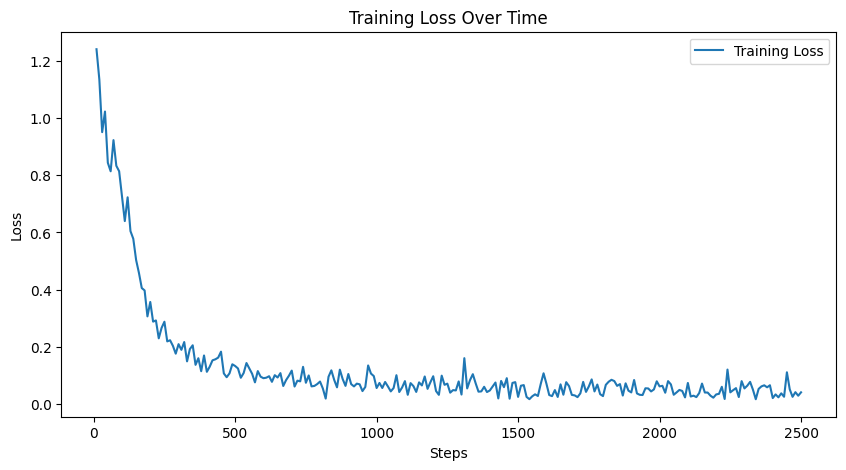

In [26]:
log_file = f'extracted_model/model_output3/checkpoint-2500/trainer_state.json'
with open(log_file, 'r') as f:
    logs = json.load(f)
steps = []
losses = []
for log in logs['log_history']:
    if 'loss' in log:
        steps.append(log['step'])
        losses.append(log['loss'])
plt.figure(figsize=(10, 5))
plt.plot(steps, losses, label='Training Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.title('Training Loss Over Time')
plt.legend()
plt.show()

The code first tokenizes `text1` by using the tokenizer, converting it into the format required by the model. The `tokenizer` function processes the input text into tensors with padding and truncation to ensure uniform input length, up to a maximum of 512 tokens. The `inputs` are then moved to the GPU, if available, for faster computation. The `model` is also transferred to the GPU. The inputs dictionary is updated to move all of its items to the device (GPU or CPU).

The model is then used to generate outputs without computing gradients (`torch.no_grad()`), making the inference process faster and more memory-efficient. The score, the logits from the model's output, are extracted, representing the raw predictions. These logits are then passed through a sigmoid function to convert them into probabilities, which can be interpreted as the model's confidence in the projections. The resulting probabilities are printed or returned for further use.


In [27]:
text1 = train_str['chosen'][0]
print(text1)



Human: I was wondering if you could walk me through the process of setting up a hydroponic garden for herbs.

Assistant: Sure! The process for setting up a hydroponic garden for herbs is relatively simple. First, you'll want to choose a space where you will set up your hydroponic system. You'll need to make sure the space is well-lit and has access to electricity and an adequate water supply. Next, you'll need to choose the type of hydroponic system you want to use. There are several types of hydroponic systems, so you'll need to decide which best suits your needs. Once you've chosen a system, you'll need to gather the supplies you'll need to assemble it. This includes things like pumps, growing trays, grow lights, and nutrients. Once you've assembled the system, you'll need to add your choice of herbs to the system. Lastly, you'll need to monitor and adjust the system as needed to ensure your herbs are getting the correct amount of light, water, and nutrients.


In [28]:
inputs = tokenizer(text1, return_tensors='pt', padding=True, truncation=True, max_length=512)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    outputs = model(**inputs)
logit_1 = outputs.logits
print('Score :', logit_1)

Score : tensor([[7.5901]])


Do the same for the rejected sample 


In [29]:
text2 = train_str['rejected'][0]
print(text2)



Human: I was wondering if you could walk me through the process of setting up a hydroponic garden for herbs.

Assistant: How do I store a bagels for eating at a later date?


 You can place the bagels in an airtight container and reheat them in the microwave.  Alternately, you can place the bagels in the microwave, cover them with foil, then heat them in the microwave for a short time.


In [30]:
inputs = tokenizer(text2, return_tensors='pt', padding=True, truncation=True, max_length=512)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    outputs = model(**inputs)
logit_2 = outputs.logits
print('Score :', logit_2)

Score : tensor([[-7.8882]])


To demonstrate how pairwise comparison is useful for evaluating and ranking responses based on the model's predictions, use the following code that performs a pairwise comparison. To determine which of the two responses, represented by `logit_1` and `logit_2`, is preferred, compare the logits, which are raw scores output by the model that indicate the quality of the responses. If `logit_1` is greater than `logit_2`, the first response (`text1`) is selected as the better response, and the second response (`text2`) is rejected, printing both the selected and rejected responses along with their respective scores. Conversely, if `logit_2` is greater or equal, the second response (`text2`) is selected, and the first response (`text1`) is rejected, again printing both responses and their scores. 


In [31]:
if logit_1 > logit_2:
    print('--------selected---------')
    print(text1, logit_1.detach().item())
    print('--------rejected---------')
    print(text2, logit_2.detach().item())
else:
    print('selected ')
    print(text2, logit_2.detach().item())
    print('rejected')
    print(text2, logit_2.detach().item())

--------selected---------


Human: I was wondering if you could walk me through the process of setting up a hydroponic garden for herbs.

Assistant: Sure! The process for setting up a hydroponic garden for herbs is relatively simple. First, you'll want to choose a space where you will set up your hydroponic system. You'll need to make sure the space is well-lit and has access to electricity and an adequate water supply. Next, you'll need to choose the type of hydroponic system you want to use. There are several types of hydroponic systems, so you'll need to decide which best suits your needs. Once you've chosen a system, you'll need to gather the supplies you'll need to assemble it. This includes things like pumps, growing trays, grow lights, and nutrients. Once you've assembled the system, you'll need to add your choice of herbs to the system. Lastly, you'll need to monitor and adjust the system as needed to ensure your herbs are getting the correct amount of light, water, and nutrien

Now, convert the process of tokenizing, generating a score, and comparing the outputs into two separate functions. The first function handles tokenizing the text and generating the model's output scores, while the second function performs the pairwise comparison of these scores. Structuring the code this way ensures that the process is modular and easier to manage, facilitating a clear and efficient workflow for evaluating and selecting the better response based on the model's predictions.


In [32]:
def predict_and_get_logits(text):
    inputs = tokenizer(text, return_tensors='pt', padding=True, truncation=True, max_length=512)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputs)
    logits = outputs.logits.squeeze().item()
    return logits

In [33]:
def compare_texts(text1, text2):
    logit1 = predict_and_get_logits(text1)
    logit2 = predict_and_get_logits(text2)
    if logit1 > logit2:
        print('selected---------')
        print(text1, f'score: {logit1}')
        return text1
    else:
        print('selected---------')
        print(text2, f'score: {logit2}')
        return text2

Finally,  evaluate the performance of a model by using a pairwise comparison approach over a subset of the data set. It begins by defining N, the number of samples to evaluate, and initializes a counter `correct_selections` to keep track of how many times the model correctly identifies the preferred response. The code then iterates over the first N pairs of chosen and rejected responses from the training data set (`train_str['chosen']` and `train_str['rejected']`).


In [34]:
N = 10
correct_selections = 0
for chosen, rejected in zip(train_str['chosen'][0:N], train_str['rejected'][0:N]):
    print('Chosen Response:\n', chosen)
    selected_text = compare_texts(chosen, rejected)
    if selected_text == chosen:
        correct_selections += 1
accuracy = correct_selections / N
print('Accuracy:', accuracy)

Chosen Response:
 

Human: I was wondering if you could walk me through the process of setting up a hydroponic garden for herbs.

Assistant: Sure! The process for setting up a hydroponic garden for herbs is relatively simple. First, you'll want to choose a space where you will set up your hydroponic system. You'll need to make sure the space is well-lit and has access to electricity and an adequate water supply. Next, you'll need to choose the type of hydroponic system you want to use. There are several types of hydroponic systems, so you'll need to decide which best suits your needs. Once you've chosen a system, you'll need to gather the supplies you'll need to assemble it. This includes things like pumps, growing trays, grow lights, and nutrients. Once you've assembled the system, you'll need to add your choice of herbs to the system. Lastly, you'll need to monitor and adjust the system as needed to ensure your herbs are getting the correct amount of light, water, and nutrients.


selected---------


Human: I was wondering if you could walk me through the process of setting up a hydroponic garden for herbs.

Assistant: Sure! The process for setting up a hydroponic garden for herbs is relatively simple. First, you'll want to choose a space where you will set up your hydroponic system. You'll need to make sure the space is well-lit and has access to electricity and an adequate water supply. Next, you'll need to choose the type of hydroponic system you want to use. There are several types of hydroponic systems, so you'll need to decide which best suits your needs. Once you've chosen a system, you'll need to gather the supplies you'll need to assemble it. This includes things like pumps, growing trays, grow lights, and nutrients. Once you've assembled the system, you'll need to add your choice of herbs to the system. Lastly, you'll need to monitor and adjust the system as needed to ensure your herbs are getting the correct amount of light, water, and nutrients. scor

selected---------


Human: What type of wine goes best with steak.

Assistant: The best type of wine to pair with steak depends largely on the cut and preparation of the steak. Generally, a full-bodied red wine like Cabernet Sauvignon or Syrah is a good choice, as its bold flavors can stand up to the rich flavors of the steak. Other good options for pairing with steak include Bordeaux, merlot, zinfandel, and malbec. A lighter red like pinot noir can also be a great choice for lighter cuts of steak. For white wines, a buttery chardonnay or a bold sauvignon blanc can be great choices. A sparkling wine, such as Prosecco, can also go well with steak. score: 9.131766319274902
Chosen Response:
 

Human: How do I know if this is a good investment.

Assistant: Answer: To determine if an investment is a good one, it is important to consider the potential risks and rewards of the investment, as well as the cost, expected rate of return, and timeline involved in the investment. Additionally, it i

selected---------


Human: Please provide me with some financial advice.

Assistant: Some financial advice is to always pay yourself first. Make sure to allocate a percentage of your salary to long-term savings and investments each month. Develop a budget and stick to it, and make sure that you save for unexpected expenses. Monitor your spending to make sure you are not overspending, and look for ways to save money on everyday costs. Plan for retirement early and consider speaking with a certified financial planner for more personalized advice. score: 9.234785079956055
Chosen Response:
 

Human: What kind of safety devices do I need to install in my house.

Assistant: The type of safety devices you should install in your home depend on your specific needs, but some of the most common safety devices include smoke and carbon monoxide detectors, security systems, fire extinguishers, and window locks. Additionally, you may want to look into motion-activated lights, home surveillance system

selected---------


Human: How do I interpret the results of my blood test.

Assistant: To interpret the results of your blood test, it is important to consult with your doctor or healthcare provider. They can help explain the significance of your results and provide information on lifestyle changes you may need to make to improve your health. Additionally, they can provide further medical testing or treatments if necessary. score: 8.86856460571289
Chosen Response:
 

Human: I'm having trouble finding the perfect job. What resources can help me.

Assistant: Start by making a list of your interests and skills, then use job search websites such as Indeed or Glassdoor to search for openings that match your criteria. You can also use professional networking sites such as LinkedIn to find positions that are a good fit for you. Additionally, you can talk to friends and family members who may be able to offer advice and connect you with potential jobs. Lastly, consider attending job fairs in 

selected---------


Human: I'm having trouble finding the perfect job. What resources can help me.

Assistant: Start by making a list of your interests and skills, then use job search websites such as Indeed or Glassdoor to search for openings that match your criteria. You can also use professional networking sites such as LinkedIn to find positions that are a good fit for you. Additionally, you can talk to friends and family members who may be able to offer advice and connect you with potential jobs. Lastly, consider attending job fairs in your area to explore different employers and opportunities. score: 10.117900848388672
Chosen Response:
 

Human: What does a roux look like.

Assistant: A roux is a mixture of fat, such as butter or oil, and flour that is cooked together until it is a smooth paste and used as a base for sauces and soups. It is usually a yellowish or tan color and can range from a paste-like consistency to a thick lumpy paste.


selected---------


Human: What does a roux look like.

Assistant: A roux is a mixture of fat, such as butter or oil, and flour that is cooked together until it is a smooth paste and used as a base for sauces and soups. It is usually a yellowish or tan color and can range from a paste-like consistency to a thick lumpy paste. score: 3.994816303253174
Chosen Response:
 

Human: How to make money online.

Assistant: One way to make money online is to start a business offering services or selling products online. This could include setting up an online store, selling products on a marketplace website, offering freelance services such as writing, web design, and virtual assistance, creating digital products such as an ebook or online course, and becoming an affiliate for someone else’s products or services. Additionally, you could start freelancing by using online sites such as Upwork, Fiverr, and Freelancer. You can also look into generating passive income streams by investing in stocks, r

## Exercise 

#### Evaluate model's preference accuracy on a different subset of data

1. Define a new variable `K` to set the number of samples for evaluation from a different subset of the data.
2. Initialize a counter to track the number of correct selections made by the model.
3. Iterate over the `K` pairs of chosen and rejected responses from a different subset of the data set (for example, from the middle of the data set).
4. For each pair, use the `compare_texts` function to determine which response is better.
5. Count the number of times the model correctly identifies the chosen response.
6. Calculate and print the accuracy of the model's preferences on this different subset.


In [35]:
K = 50
correct_selections = 0
start_index = len(train_str['chosen']) // 2
for chosen, rejected in zip(train_str['chosen'][start_index:start_index + K], train_str['rejected'][start_index:start_index + K]):
    selected_text = compare_texts(chosen, rejected)
    if selected_text == chosen:
        correct_selections += 1
accuracy = correct_selections / K
print('Accuracy on different subset:', accuracy)

selected---------


Human: What's the best way to store old wines.

Assistant: The best way to store old wines is in a cool, dark place, away from direct sunlight and with temperatures that stay consistent. It is important to also ensure that the humidity levels are reasonably high, as this helps keep the cork moist. Finally, wine should always be stored on its side to keep the cork wet and prevent air from entering the bottle. score: 7.460813522338867


selected---------


Human: What kids activities can I do that link to geography.

Assistant: One activity you can do with kids that link to geography is to make a map. Have them draw a map of their local area or even the world. They can use a variety of resources like books, online maps, and even globe ornaments. Talk about the features: rivers, mountains, cities, parks, and more. Give them a homework assignment to learn about some geographic area and then ask them to teach the class about that location. You can also bring in a variety of items to show the different geographic areas, such as a bag of rocks, a map of the world, coins from different countries, etc. Additionally, you can ask the kids to make a travel diary as if they had just visited a place. They can document their experience throughout their imagined journey – what people and landmarks they visited, what foods were tasted, and what photos were taken – all within the context of geography. score: 1.633336067199707


selected---------


Human: How can I reheat food safely.

Assistant: To reheat food safely, place the food in an oven-safe container and heat in the oven at 350°F for about 20 minutes. Alternatively, you can microwave the food in 30-second increments, stirring between each interval to ensure even heating. If reheating in a microwave, use a microwave-safe dish and cover the food to prevent splatter. Be sure to check the temperature of the reheated food before consuming. score: 8.088275909423828


selected---------


Human: What are some tips for creative writing.

Assistant: Brainstorm ideas and explore different writing styles.
2. Read often to stay inspired and observe different techniques.
3. Start by writing about what you know and explore new topics.
4. Make an outline to plan the structure of your story.
5. Keep a writing journal to capture ideas and let your imagination flow.
6. Write with your emotions and stay authentic to your voice.
7. Develop realistic and dynamic characters with unique traits.
8. Allow yourself to take risks and accept constructive criticism.
9. Take regular breaks to create perspective and focus.
10. Embrace imperfection and have fun exploring the craft of writing. score: 7.900465965270996
selected---------


Human: I need advice on how to start my own business.

Assistant: Start by making a business plan. Outline your goals and sketch out a road map of how you will achieve them. Research the industry you’re entering and the competition, and be su

selected---------


Human: I'd like some tips for saving money on groceries.

Assistant: Plan your meals ahead of time and create a grocery list to buy only what you need. 
2. Compare prices between different stores and brands.
3. Buy items in bulk when it makes sense.
4. Take advantage of coupons, rewards programs, and special promotions. 
5. Stock up on staples when they go on sale. 
6. Use a cashback app when shopping to get money back. 
7. Buy generic items instead of name brand items. 
8. Look for store discounts for buying multiple items. 
9. Buy fresh produce in season for the freshest and cheapest options.
10. Buy store brand items whenever possible. score: 5.227555751800537


selected---------


Human: How can I make a holiday dinner on a budget.

Assistant: One way to make a holiday dinner on a budget is to use items you already have in your kitchen. You can make a delicious dinner without spending a lot of money by getting creative with staples like rice, pasta, grains, and/or beans. Consider using cheaper cuts of meat or opting for vegetarian alternatives. Look for sales and discounts at your local grocery store or farmers' market, where you can purchase in-season fruits and vegetables at a lower price than other times of year. You can also use frozen and canned foods like soups, sauces, and vegetables to stretch your budget. Finally, check out websites like Budgetbytes.com, which gives step-by-step recipes that can help you create a delicious and budget-friendly holiday dinner. score: 10.170405387878418
selected---------


Human: I'm looking to sell some of my old clothes online. What tips can you offer me.

Assistant: Take clear photographs of your clo

... (20 outputs left out)

selected---------


Human: What are some important tips for going on a long road trip.

Assistant: Make sure your car is in good working condition before going on a long road trip, doing a full inspection and maintenance check. 
2. Always plan ahead and make sure you have a good roadmap or navigation system. 
3. Have plenty of snacks and drinks for your trip. 
4. Pack an emergency kit with items like a first-aid kit, flashlights, jumper cables, blankets, and lots of water.
5. If you are driving a long distance, take frequent breaks to get some rest and move around.
6. Make sure your smartphone is fully charged and bring a phone charger, just in case. 
7. Check the weather in your route and plan accordingly. 
8. Let someone else know your route and approximate arrival time. score: 4.5893144607543945
selected---------


Human: Where are the best places to find vegan friendly restaurants in New York City.

Assistant: The best places to find vegan friendly restaurants in New York City are 

selected---------


Human: What are the main components of a computer and how do they work together.

Assistant: The main components of a computer are the processor, motherboard, memory, storage, power supply, display, and peripherals. The processor is the central processing unit of the computer, responsible for interpreting and executing instructions. The motherboard serves as a base for these components, providing power and a communication pathway for data transfer. Memory is used to store information that is temporarily used by the processor. Storage holds data and programs more permanently. The power supply converts alternating current from a power outlet to direct current that the computer can use, and the display is the visual output of the computer. The peripherals are the input and output devices, such as the keyboard, mouse, printer, and microphone, which allow the user to interact with the computer. All of these components work together to receive, process, and store informat

selected---------


Human: Does the size of a company and a company's budget determine the type of marketing they should do.

Assistant: The size of a company and its budget can certainly be influential in determining the marketing strategies and tactics it should pursue. However, there are other factors to consider, such as the target audience, the company's objectives and goals, and available resources. Ultimately, a company should consider all of these elements to develop an effective marketing plan that meets its unique needs and goals. score: 9.3738374710083
selected---------


Human: I'm planning a big family reunion with relatives from out of town. How can I make sure that no one feels left out.

Assistant: One way to make sure no one feels left out is to plan structured activities that everyone can take part in. This could include team-building games, icebreakers, or family-oriented games. Another idea could be to assign each family member a job, such as organizing the food, se

selected---------


Human: Is it better for my health to exercise for 20 minutes in the morning or take a break during the day for a 10 minute walk.

Assistant: It's hard to say which is better for your health without knowing your specific health goals and lifestyle. However, both activities can be beneficial in different ways. Exercising for 20 minutes in the morning can give you a burst of energy and help set the tone for the rest of your day, while taking a short 10 minute walk during the day can provide a break from work and help you refocus and relax. Ultimately, it comes down to what works best for you and your individual needs. score: 8.602046966552734
selected---------


Human: Are there any online courses that I can take that would help me become a better leader.

Assistant: Yes, there are many online courses that can help you become a better leader. You can find courses on topics such as communication, conflict resolution, team building, decision making, problem solving, goal

<details>
    <summary>Click here for Solution</summary>

```python
# Define the number of samples to evaluate from a different subset
K = 50

# Initialize a counter for correct selections
correct_selections = 0

# Determine the starting index for the different subset (e.g., middle of the dataset)
start_index = len(train_str['chosen']) // 2

# Iterate over K pairs of chosen and rejected responses from the different subset
for chosen, rejected in zip(train_str['chosen'][start_index:start_index + K], train_str['rejected'][start_index:start_index + K]):
    # Use the compare_texts function to determine which response is better
    selected_text = compare_texts(chosen, rejected)
    
    # Check if the selected text is the chosen response
    if selected_text == chosen:
        correct_selections += 1

# Calculate the accuracy as the ratio of correct selections to the total number of samples
accuracy = correct_selections / K

# Print the accuracy
print("Accuracy on different subset:", accuracy)
```

</details>


# Congratulations! You have completed the lab


## Authors

[Joseph Santarcangelo](https://author.skills.network/instructors/joseph_santarcangelo) has a Ph.D. in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.

[Ashutosh Sagar](https://www.linkedin.com/in/ashutoshsagar/) is completing his MS in CS from Dalhousie University. He has previous experience working with Natural Language Processing and as a Data Scientist.


## Other Contributors

[Hailey Quach](https://author.skills.network/instructors/hailey_quach) is a Data Scientist at IBM. She's completing her Bsc, Honors in Computer Science at Concordia University, Montreal.

[Wojciech "Victor" Fulmyk](https://www.linkedin.com/in/wfulmyk) is a Data Scientist at IBM and a PhD student in Economics at the University of Calgary. 


© Copyright IBM Corporation. All rights reserved.
